In [3]:
import pandas as pd
import nltk

from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [4]:
from google.colab import files
uploaded = files.upload()

Saving ronaldo_text_clean.csv to ronaldo_text_clean.csv


In [5]:
data_clean = pd.read_csv('ronaldo_text_clean.csv')

print("Jumlah data:", len(data_clean))

# Tampilkan seluruh baris dan teks secara lengkap
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

display(data_clean)

Jumlah data: 565


,text_clean
0,as my final act of love for ronaldo i will become the most disciplined focused and obsessed version of myself win or lose does not matter but i will never quit without a fight no matter how bad it hurts how lonely it gets or how sad i feel i will never give up on my dream
1,the biggest shock for me out of this ronaldo drama is what the portuguese are saying about him i had zero idea the resentment they had for him in the latter years
2,breaking zlatan to ronaldo after his exit from the portugal national team listen carefully i ve patiently waited for this day cristiano set the rules himself you re not a legend until you win with your country boom a straight hit at messi after 2014 the world
3,amazing stat cristiano ronaldo has scored 146 goals for portugal yet only three of them came in knockout stages which means only 0.00028 of his goals were useful for portugal
4,the ronaldo and jorge jesus saga
5,just in portugal prime minster luis montenegro has asked to speak to jorge jesus because he wants full clarity on cristiano ronaldo
6,appreciate cristiano ronaldo most international goals 146 most international appearances 234 most consecutive years scoring 25 most goals scored at the european championship 14 most fifa world cup goals for portugal 11 oldest man to score multiple
7,cristiano ronaldo bombshell cristiano ronaldo is reportedly considering a huge decision that could change his children s national identity reports claim the portuguese superstar wants his five children to take argentine nationality the country of his wife
8,breaking here are the countries which christiano ronaldo junior can play for in nations football top 5 united states born country spain top residence since born cape verde grandmother s side portugal father s r hate
9,portugal before ronaldo only qualified for 3 world cups only qualified for 3 euros no major trophies portugal since ronaldo qualified for 6 world cups qualified for 6 euros won 3 major trophies


In [6]:
data_list = data_clean.text_clean.to_list()
data_list[:10]

['as my final act of love for ronaldo i will become the most disciplined focused and obsessed version of myself win or lose does not matter but i will never quit without a fight no matter how bad it hurts how lonely it gets or how sad i feel i will never give up on my dream',
 'the biggest shock for me out of this ronaldo drama is what the portuguese are saying about him i had zero idea the resentment they had for him in the latter years',
 'breaking zlatan to ronaldo after his exit from the portugal national team listen carefully i ve patiently waited for this day cristiano set the rules himself you re not a legend until you win with your country boom a straight hit at messi after 2014 the world',
 'amazing stat cristiano ronaldo has scored 146 goals for portugal yet only three of them came in knockout stages which means only 0.00028 of his goals were useful for portugal',
 'the ronaldo and jorge jesus saga',
 'just in portugal prime minster luis montenegro has asked to speak to jorge

In [7]:
additional = {
    'ronaldo', 'cristiano', 'cr7',
    'https', 'http', 'amp', 'rt',
    'www', 'com', 'via',
    'like', 'time', 'even',
    'football'
}

In [8]:
# Menggabungkan stopwords bahasa Inggris dari NLTK dengan stopwords tambahan
stopwords_nltk = set(stopwords.words('english'))

final_stopwords = stopwords_nltk.union(additional)

print("Jumlah stopwords NLTK:", len(stopwords_nltk))
print("Jumlah stopwords tambahan:", len(additional))
print("Jumlah final stopwords:", len(final_stopwords))

Jumlah stopwords NLTK: 198
Jumlah stopwords tambahan: 14
Jumlah final stopwords: 212


In [9]:
vectorizer = TfidfVectorizer(
    stop_words=list(final_stopwords),
    max_df=0.85,
    min_df=2,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X = vectorizer.fit_transform(data_list)

print("Ukuran matriks TF-IDF:", X.shape)

Ukuran matriks TF-IDF: (565, 1284)


In [10]:
model = KMeans(
    n_clusters=3,
    init='k-means++',
    max_iter=100,
    n_init=1,
    random_state=42
)

model.fit(X)

data_clean['cluster'] = model.labels_

print(data_clean['cluster'].value_counts().sort_index())

cluster
0    334
1    142
2     89
Name: count, dtype: int64


In [11]:
terms = vectorizer.get_feature_names_out() # ambil daftar semua kata (nama kolom matriks)
order_centroids = model.cluster_centers_.argsort()[:, ::-1] # urutkan kata di tiap cluster dari bobot terbesar ke terkecil

for i in range(3): # ulangi untuk cluster 0, 1, 2
    subset = data_clean[data_clean['cluster'] == i]
    top_words = [terms[ind] for ind in order_centroids[i, :5]]

    print("\n" + "=" * 50)
    print(f"CLUSTER {i}")
    print("Jumlah postingan:", len(subset))
    print("Lima kata dominan:", ", ".join(top_words))

    print("\nContoh postingan:")
    contoh = subset['text_clean'].sample(
        n=min(3, len(subset)),
        random_state=42
    )

    for nomor, tweet in enumerate(contoh, start=1):
        print(f"{nomor}. {tweet}")


CLUSTER 0
Jumlah postingan: 334
Lima kata dominan: portugal, player, man, say, still

Contoh postingan:
1. cristiano ronaldo is back at al nassr while the uefa nations league continues ronaldo has returned to his club after leaving the portugal national team camp the goat is back in saudi arabia
2. says ronaldo ids a narcissist but search up yamal s name on his feed and you ll see the amount of lockdown defending he does to prove he s sum humble confident wonderkid for doing exactly what cr7 has always done and backed up
3. ronaldo jnr showing off his skills

CLUSTER 1
Jumlah postingan: 142
Lima kata dominan: messi, fans, farewell, lionel messi, lionel

Contoh postingan:
1. cristiano ronaldo commented on lionel messi s retirement post saying leo s legacy with argentina will endure forever and expressing his respect for everything messi accomplished
2. question to all the manchester city fans that idolize messi what exactly has messi done for manchester city that you idolize him and yo

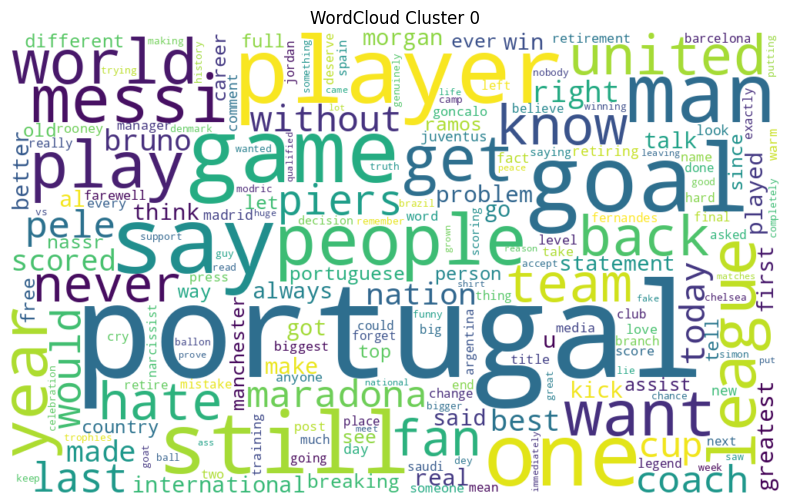

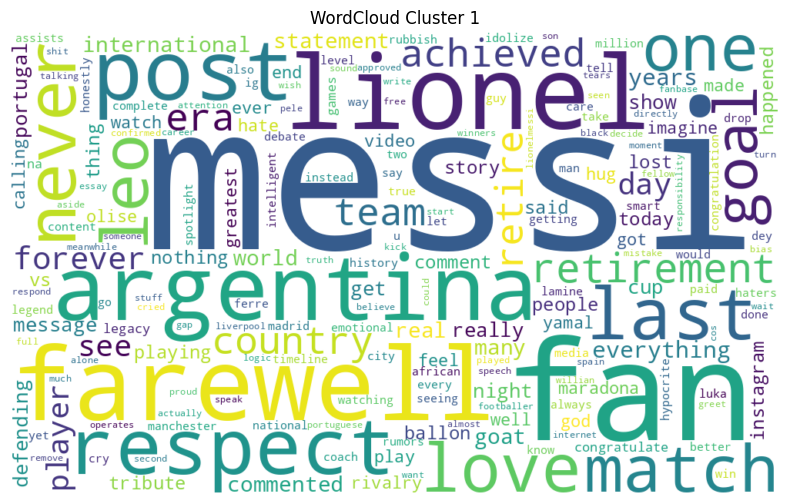

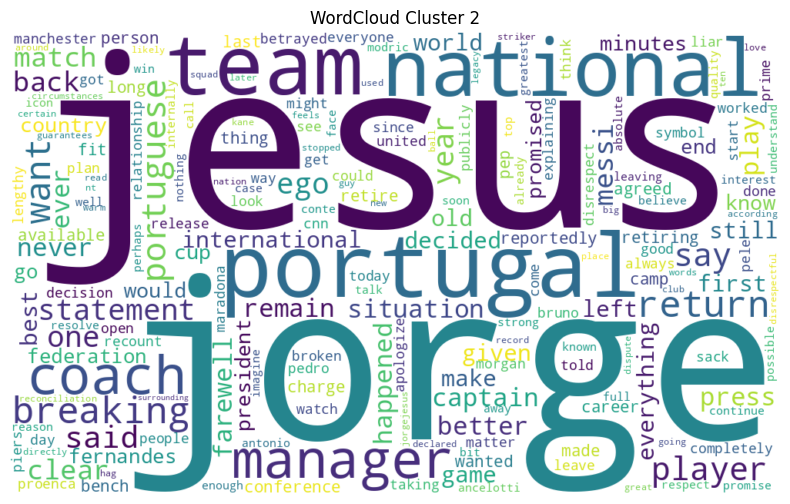

In [12]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Stopwords tambahan
additional = {
    'ronaldo', 'cristiano', 'cr7',
    'https', 'http', 'amp', 'rt',
    'www', 'com', 'via',
    'like', 'time', 'even',
    'football'
}

# Pastikan final_stopwords tersedia
final_stopwords = set(stopwords.words('english')).union(additional)

# WordCloud untuk setiap cluster
for cluster_id in sorted(data_clean['cluster'].dropna().unique()):

    # Ambil teks berdasarkan cluster
    cluster_text = ' '.join(
        data_clean.loc[
            data_clean['cluster'] == cluster_id,
            'text_clean'
        ].fillna('').astype(str)
    )

    if not cluster_text.strip():
        print(f"Cluster {cluster_id} tidak memiliki teks.")
        continue

    # Buat WordCloud
    wc = WordCloud(
        stopwords=list(final_stopwords),
        width=1000,
        height=600,
        background_color='white',
        collocations=False
    ).generate(cluster_text)

    # Tampilkan visualisasi
    plt.figure(figsize=(10, 6))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'WordCloud Cluster {cluster_id}')
    plt.show()

In [13]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X, model.labels_)

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.0126


In [14]:
cluster_themes = {
    0: "Fan Debate on Portugal and GOAT Status",
    1: "Farewell to Messi",
    2: "Jorge Jesus Controversy"
}

for i in sorted(data_clean['cluster'].unique()):
    jumlah = (data_clean['cluster'] == i).sum()
    persentase = jumlah / len(data_clean) * 100

    print(f"Cluster {i}: {jumlah} postingan ({persentase:.1f}%)")
    print(f"Tema: {cluster_themes[i]}")
    print("-" * 40)

Cluster 0: 334 postingan (59.1%)
Tema: Fan Debate on Portugal and GOAT Status
----------------------------------------
Cluster 1: 142 postingan (25.1%)
Tema: Farewell to Messi
----------------------------------------
Cluster 2: 89 postingan (15.8%)
Tema: Jorge Jesus Controversy
----------------------------------------


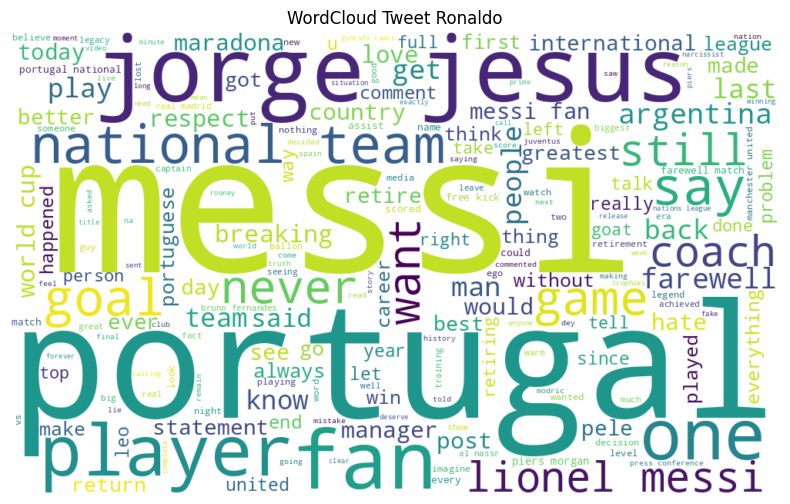

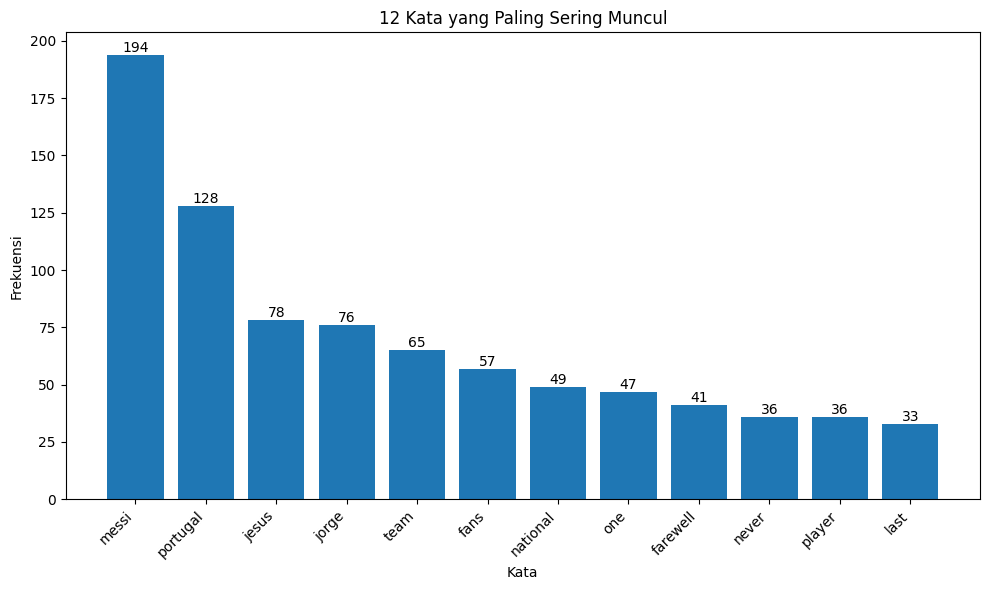

In [15]:
import pandas as pd
import nltk
import matplotlib.pyplot as plt

from nltk.corpus import stopwords
from wordcloud import WordCloud
from collections import Counter

# 1. Siapkan stopwords
nltk.download('stopwords', quiet=True)

additional = {
    'ronaldo', 'cristiano', 'cr7',
    'https', 'http', 'amp', 'rt',
    'www', 'com', 'via',
    'like', 'time', 'even',
    'football'
}

final_stopwords = set(stopwords.words('english')).union(additional)

# 2. Siapkan teks
# Menggunakan data_list jika masih tersedia
try:
    data_text = ' '.join(data_list)
except NameError:
    # Jika data_list juga hilang, unggah ulang file CSV
    from google.colab import files
    uploaded = files.upload()

    filename = next(iter(uploaded.keys()))
    data_clean = pd.read_csv(filename)

    data_list = (
        data_clean['text_clean']
        .fillna('')
        .astype(str)
        .tolist()
    )
    data_text = ' '.join(data_list)

# 3. WordCloud
wc = WordCloud(
    stopwords=final_stopwords,
    width=1000,
    height=600,
    background_color='white'
).generate(data_text)

plt.figure(figsize=(10, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud Tweet Ronaldo')
plt.show()

# 4. Grafik 12 kata paling sering muncul
words = [
    word.lower().strip(".,!?;:'\"()[]{}")
    for word in data_text.split()
]

words = [
    word for word in words
    if word and word not in final_stopwords
]

top_words = Counter(words).most_common(12)

if top_words:
    labels, counts = zip(*top_words)

    plt.figure(figsize=(10, 6))
    bars = plt.bar(labels, counts)

    plt.xlabel('Kata')
    plt.ylabel('Frekuensi')
    plt.title('12 Kata yang Paling Sering Muncul')
    plt.xticks(rotation=45, ha='right')

    for bar, count in zip(bars, counts):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            str(count),
            ha='center',
            va='bottom'
        )

    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada kata yang tersisa setelah penyaringan.")

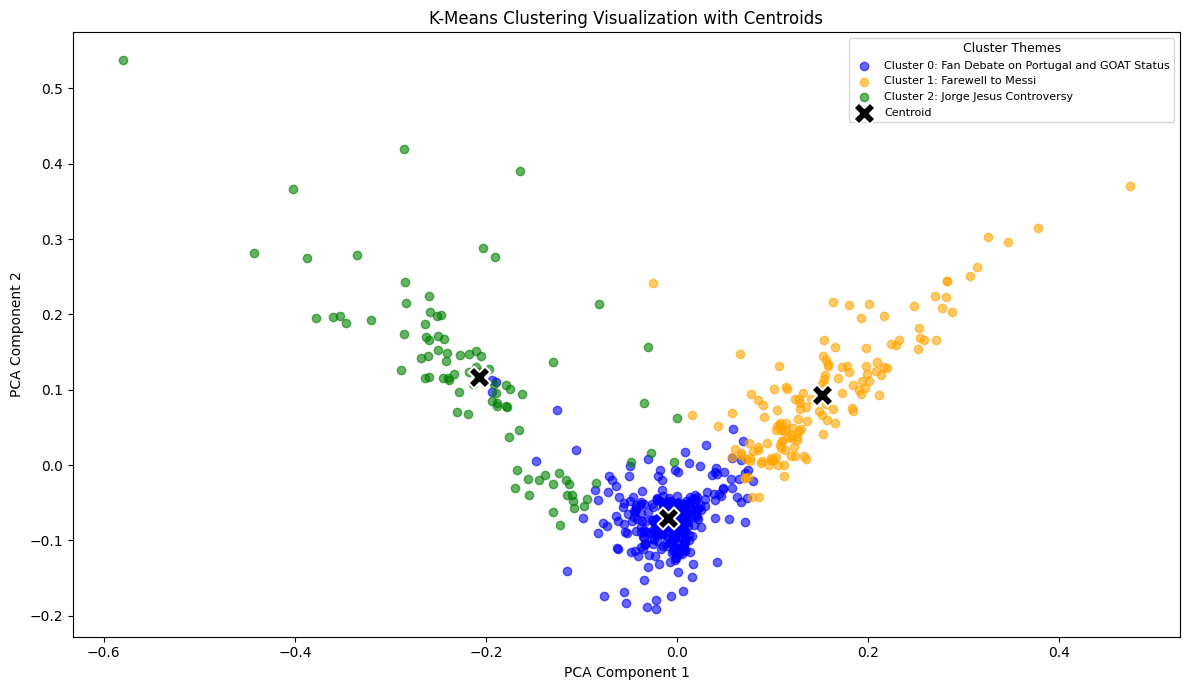

In [16]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Nama tema setiap cluster
cluster_themes = {
    0: "Fan Debate on Portugal and GOAT Status",
    1: "Farewell to Messi",
    2: "Jorge Jesus Controversy"
}

# Reduksi dimensi untuk visualisasi
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X.toarray())

plt.figure(figsize=(12, 7))

# Warna setiap cluster
colors = ['blue', 'orange', 'green']

# Plot setiap cluster dengan keterangan tema
for i in range(3):
    mask = data_clean['cluster'] == i

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        alpha=0.6,
        color=colors[i],
        label=f"Cluster {i}: {cluster_themes[i]}"
    )

# Transformasi centroid K-Means ke ruang PCA
centroids_pca = pca.transform(model.cluster_centers_)

# Plot centroid
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker='X',
    s=250,
    c='black',
    edgecolors='white',
    linewidths=1.5,
    label='Centroid'
)

plt.title("K-Means Clustering Visualization with Centroids")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")

plt.legend(
    title="Cluster Themes",
    loc="upper right",
    fontsize=8,
    title_fontsize=9,
    frameon=True
)

plt.tight_layout()
plt.show()

In [17]:
data_clean['cluster_theme'] = data_clean['cluster'].map(cluster_themes)
data_clean.to_csv('ronaldo_clustering.csv', index=False, encoding='utf-8-sig')
print("Results saved!")

Results saved!


In [18]:
from google.colab import files
files.download('ronaldo_clustering.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>